#Smart Building Energy Consumption Prediction Using Machine Learning


 Weather from the nearest airport weather station (Chievres Airport, Belgium) was downloaded from a public data set from Reliable Prognosis (rp5.ru), and merged together with the experimental data sets using the date and time column. Two random variables have been included in the data set for testing the regression models and to filter out non predictive attributes (parameters

# About Dataset:https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction

# Learning based methods:
 Supervised Learning,
 Unsupervised Learning,
 Reinforcement Learnin,


Attribute Information
date: year-month-day hour:minute:second
Appliances: energy use in Wh (watt-hour)
lights: energy use of light fixtures in the house in Wh (watt-hour)
T1: Temperature in kitchen area, in Celsius
RH_1: Humidity in kitchen area, in %
T2: Temperature in living room area, in Celsius
RH_2: Humidity in living room area, in %
T3: Temperature in laundry room area
RH_3: Humidity in laundry room area, in %
T4: Temperature in office room, in Celsius
RH_4: Humidity in office room, in %
T5: Temperature in bathroom, in Celsius
RH_5: Humidity in bathroom, in %
T6: Temperature outside the building (north side), in Celsius
RH_6: Humidity outside the building (north side), in %
T7: Temperature in ironing room , in Celsius
RH_7: Humidity in ironing room, in %
T8: Temperature in teenager room 2, in Celsius
RH_8: Humidity in teenager room 2, in %
T9: Temperature in parents room, in Celsius
RH_9: Humidity in parents room, in %
To: Temperature outside (from Chievres weather station), in Celsius
Pressure: (from Chievres weather station), in mm Hg
RH_out: Humidity outside (from Chievres weather station), in %
Wind speed: (from Chievres weather station), in m/s
Visibility: (from Chievres weather station), in km
Tdewpoint: (from Chievres weather station), Ã‚Â°C
rv1: Random variable 1, nondimensional
rv2: Random variable 2, nondimensional
Where indicated, hourly data (then interpolated) from the nearest airport weather station (Chievres Airport, Belgium) was downloaded from a public data set from Reliable Prognosis, rp5.ru. Permission was obtained from Reliable Prognosis for the distribution of the 4.5 months of weather data.

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.metrics import r2_score
from sklearn import decomposition
from sklearn.feature_selection import RFECV
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import warnings
warnings.filterwarnings('ignore')

# Set theme of plot
sns.set_theme(style="whitegrid")

# **`1. Import package`**



In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.metrics import r2_score
from sklearn import decomposition
from sklearn.feature_selection import RFECV
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import warnings
warnings.filterwarnings('ignore')

# Set theme of plot
sns.set_theme(style="whitegrid")

# 2. Read the data

In [ ]:
import pandas as pd

# Loading dataset from the official UCI repository since the local file is not found
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00374/energydata_complete.csv'
df = pd.read_csv(url)

df['date'] = pd.to_datetime(df['date'])
df.head(1000)

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.890000,47.596667,19.20,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.500000,92.0,7.000000,63.000000,5.300000,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.890000,46.693333,19.20,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.600000,92.0,6.666667,59.166667,5.200000,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.890000,46.300000,19.20,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.700000,92.0,6.333333,55.333333,5.100000,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.890000,46.066667,19.20,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.800000,92.0,6.000000,51.500000,5.000000,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.890000,46.333333,19.20,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.900000,92.0,5.666667,47.666667,4.900000,10.084097,10.084097
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,2016-01-18 14:50:00,50,0,19.390000,41.363333,18.26,41.500000,19.70,40.700000,18.890000,...,17.200000,37.90,-0.433333,757.050000,67.5,3.000000,30.833333,-5.750000,38.841700,38.841700
996,2016-01-18 15:00:00,50,0,19.290000,41.400000,18.20,41.500000,19.70,40.700000,18.890000,...,17.200000,37.79,-0.400000,757.000000,67.0,3.000000,29.000000,-5.800000,31.797492,31.797492
997,2016-01-18 15:10:00,30,0,19.356667,41.400000,18.20,41.400000,19.70,40.700000,18.890000,...,17.200000,37.79,-0.416667,756.966667,67.5,2.833333,30.833333,-5.733333,14.106815,14.106815
998,2016-01-18 15:20:00,20,0,19.290000,41.400000,18.20,41.400000,19.70,40.663333,18.856667,...,17.200000,37.79,-0.433333,756.933333,68.0,2.666667,32.666667,-5.666667,9.562973,9.562973


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         19735 non-null  datetime64[ns]
 1   Appliances   19735 non-null  int64         
 2   lights       19735 non-null  int64         
 3   T1           19735 non-null  float64       
 4   RH_1         19735 non-null  float64       
 5   T2           19735 non-null  float64       
 6   RH_2         19735 non-null  float64       
 7   T3           19735 non-null  float64       
 8   RH_3         19735 non-null  float64       
 9   T4           19735 non-null  float64       
 10  RH_4         19735 non-null  float64       
 11  T5           19735 non-null  float64       
 12  RH_5         19735 non-null  float64       
 13  T6           19735 non-null  float64       
 14  RH_6         19735 non-null  float64       
 15  T7           19735 non-null  float64       
 16  RH_7

No null values
19735 rows and 29 features
All are numerical features
Dataset contains temperature, humidity and weather information
2 random variables (non-dimensional) are given to filter non-predictive attributes

In [ ]:
# Check if any rows are duplicated!

print(f'Duplicate rows: {df.duplicated().sum()}')

Duplicate rows: 0


In [ ]:
# Check if any columns are duplicated!
temp_df = df.copy()
cols = temp_df.columns.tolist()

# rv1, rv2 are the same! TODO: Check if it has any impact on model performance
print(f'Duplicate columns: {temp_df.T.duplicated().sum()}')

Duplicate columns: 1


In [ ]:
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['hour'] = df['date'].dt.hour
df['minute'] = df['date'].dt.minute

df.drop('date', axis=1, inplace=True)
df.head()

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,month,day,hour,minute
0,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,92.0,7.000000,63.000000,5.3,13.275433,13.275433,1,11,17,0
1,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,92.0,6.666667,59.166667,5.2,18.606195,18.606195,1,11,17,10
2,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,92.0,6.333333,55.333333,5.1,28.642668,28.642668,1,11,17,20
3,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,...,92.0,6.000000,51.500000,5.0,45.410389,45.410389,1,11,17,30
4,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,...,92.0,5.666667,47.666667,4.9,10.084097,10.084097,1,11,17,40


# Exploratory Data Analysis (EDA)

In [ ]:
df.columns

Index(['Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4',
       'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9',
       'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility',
       'Tdewpoint', 'rv1', 'rv2', 'month', 'day', 'hour', 'minute'],
      dtype='object')

In [ ]:
df.shape

(19735, 32)

### Energy Usage of Appliances (Hourly, Daily, Monthly)

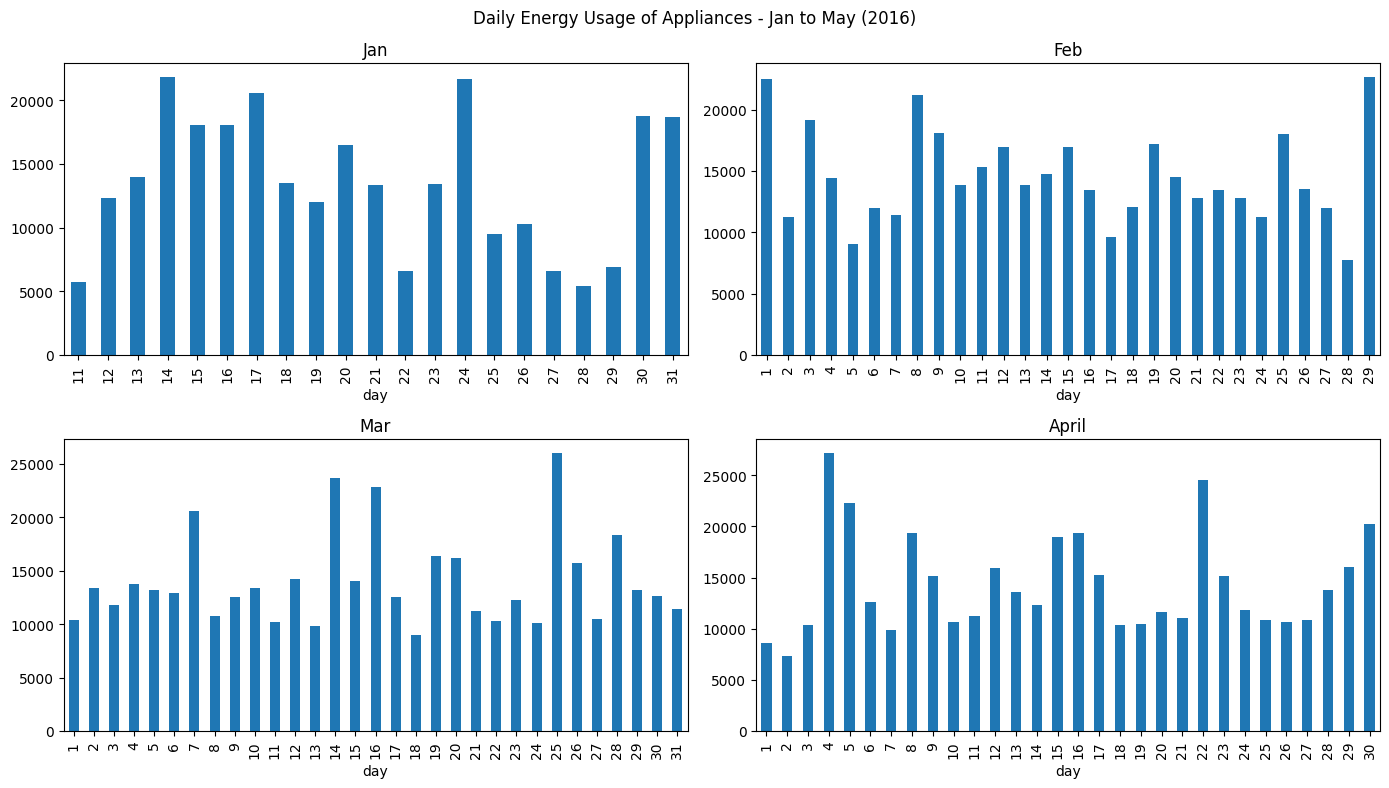

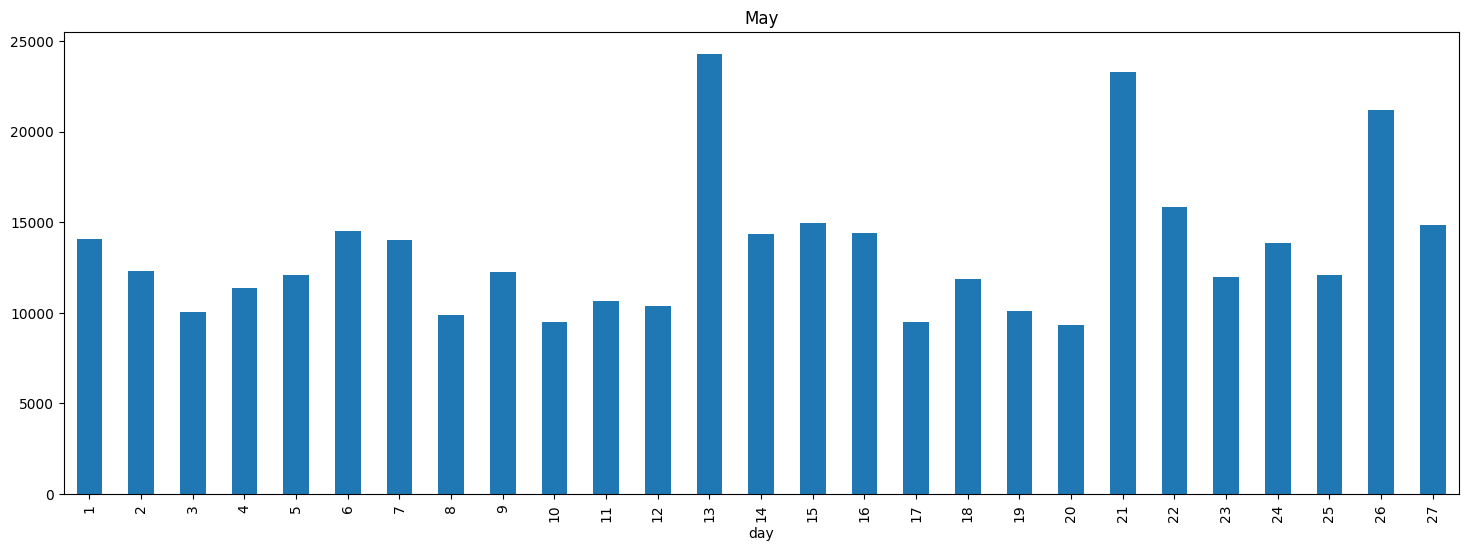

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Ensure time-based features (month, day, hour, minute) are in df
# This makes the plotting cell robust to execution order, especially after a kernel restart.
if 'month' not in df.columns and 'date' in df.columns:
    df['month'] = df['date'].dt.month
    df['day'] = df['date'].dt.day
    df['hour'] = df['date'].dt.hour
    df['minute'] = df['date'].dt.minute

# Daily energy usage
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
ax = ax.flatten()

months = ['Jan', 'Feb', 'Mar', 'April']
for i in range(1, 5):
    df.query(f"month == {i}")[['day', 'Appliances']].groupby('day')['Appliances'].sum().plot.bar(ax=ax[i-1], title=months[i-1])

plt.suptitle('Daily Energy Usage of Appliances - Jan to May (2016)')
plt.tight_layout()
plt.show()

# Plotting May month's usage
plt.figure(figsize=(18, 6))
df.query("month == 5")[['day', 'Appliances']].groupby('day')['Appliances'].sum().plot.bar(title='May')
plt.show()

Weekend energy usage is more or less higher compare to average day. E.g. Jan
Certain months shows high energy usage for pre-weekend day. Could be party, enjoyment

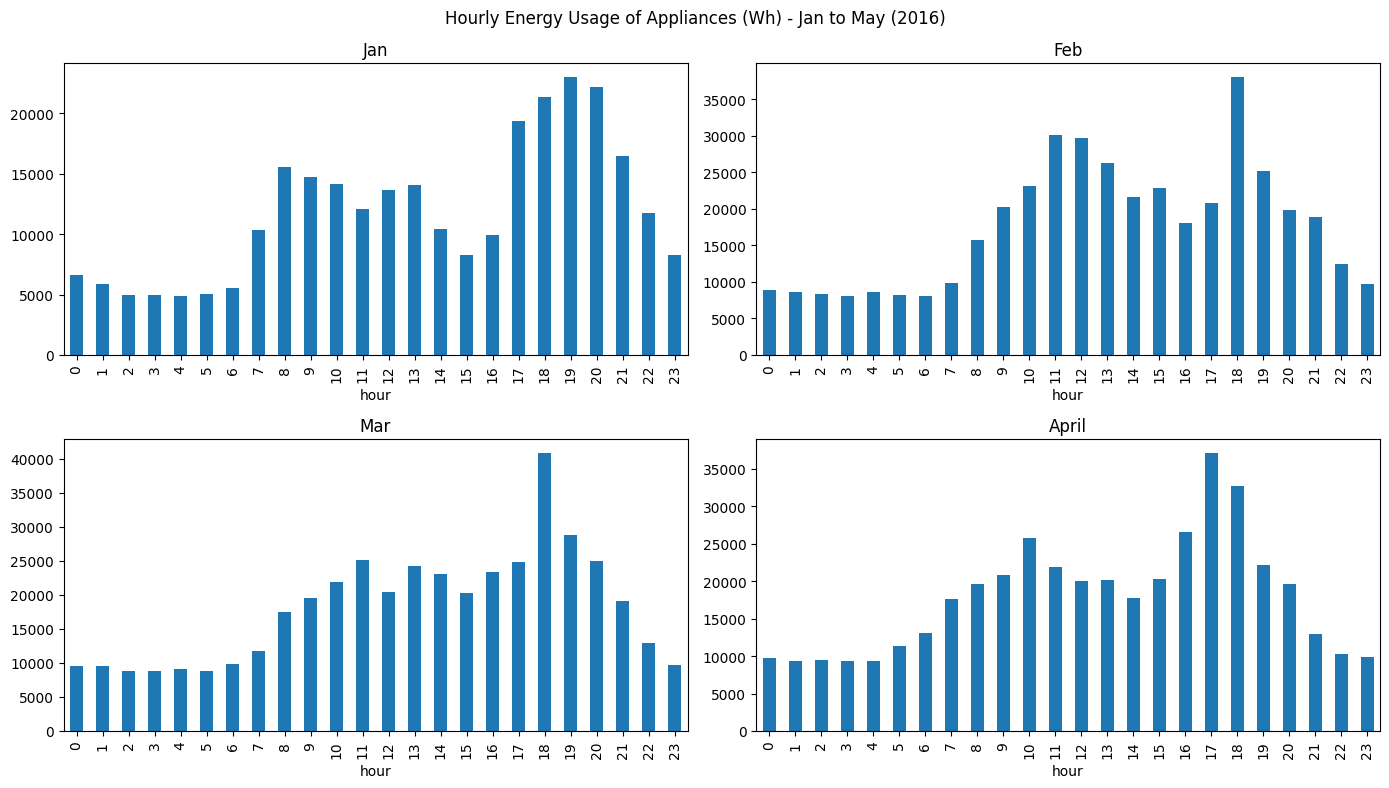

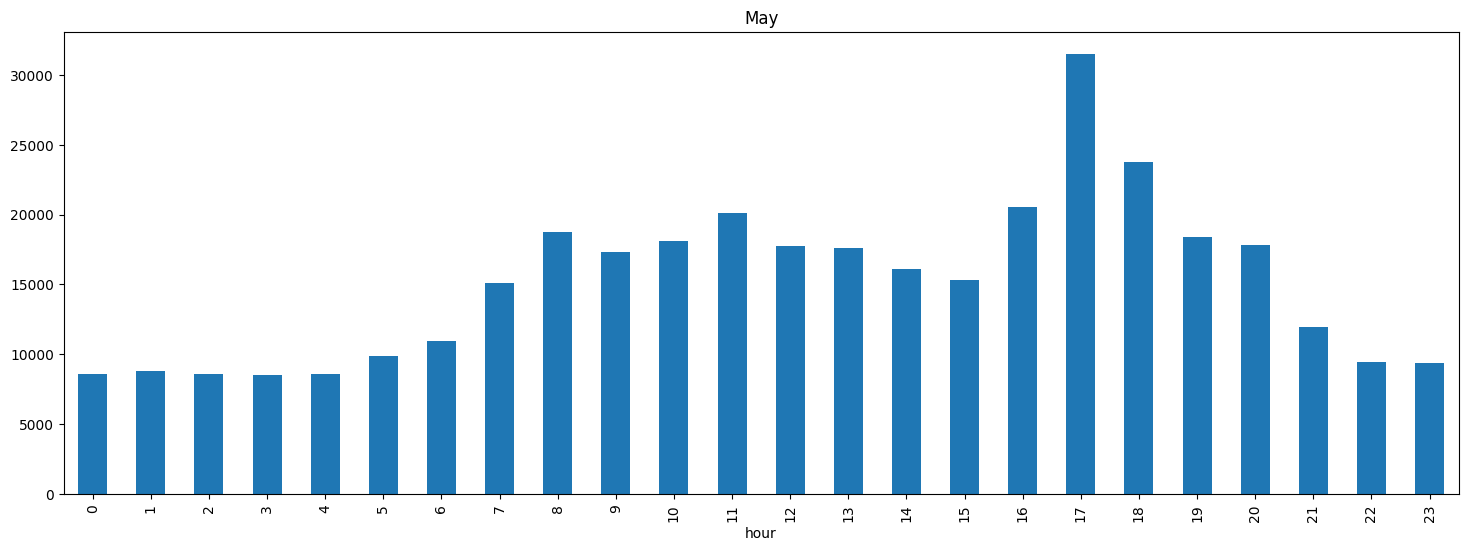

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Ensure time-based features (month, day, hour, minute) are in df
# This makes the plotting cell robust to execution order, especially after a kernel restart.
if 'month' not in df.columns and 'date' in df.columns:
    df['month'] = df['date'].dt.month
    df['day'] = df['date'].dt.day
    df['hour'] = df['date'].dt.hour
    df['minute'] = df['date'].dt.minute
elif 'date' in df.columns and 'month' not in df.columns: # If 'date' is present but not converted
    df['month'] = df['date'].dt.month
    df['day'] = df['date'].dt.day
    df['hour'] = df['date'].dt.hour
    df['minute'] = df['date'].dt.minute

# Hourly energy usage
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
ax = ax.flatten()

months = ['Jan', 'Feb', 'Mar', 'April']
for i in range(1, 5):
    df.query(f"month == {i}")[['hour', 'Appliances']].groupby('hour')['Appliances'].sum().plot.bar(ax=ax[i-1], title=months[i-1])

plt.suptitle('Hourly Energy Usage of Appliances (Wh) - Jan to May (2016)')
plt.tight_layout()
plt.show()

# Plotting May month's usage
plt.figure(figsize=(18, 6))
df.query("month == 5")[['hour', 'Appliances']].groupby('hour')['Appliances'].sum().plot.bar(title='May')
plt.show()

Energy usage in March month is higher comparatively because its a peak summer month


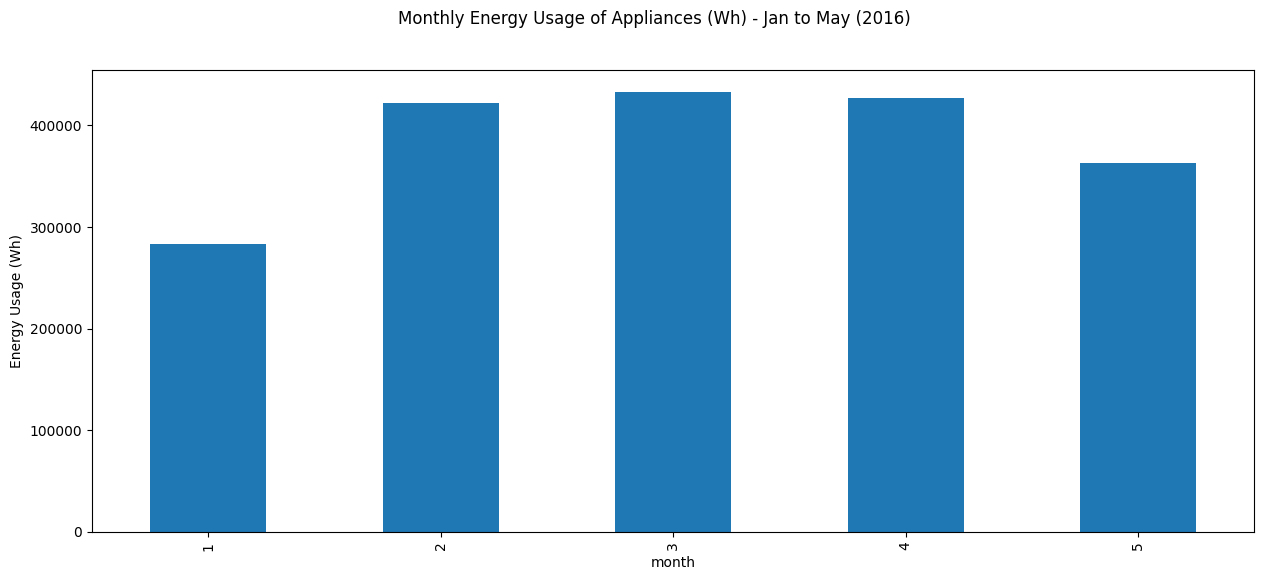

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Ensure time-based features (month, day, hour, minute) are in df
# This makes the plotting cell robust to execution order, especially after a kernel restart.
if 'month' not in df.columns and 'date' in df.columns:
    df['month'] = df['date'].dt.month
    df['day'] = df['date'].dt.day
    df['hour'] = df['date'].dt.hour
    df['minute'] = df['date'].dt.minute
elif 'date' in df.columns and 'month' not in df.columns: # If 'date' is present but not converted
    df['month'] = df['date'].dt.month
    df['day'] = df['date'].dt.day
    df['hour'] = df['date'].dt.hour
    df['minute'] = df['date'].dt.minute

# Monthly energy usage
plt.figure(figsize=(15, 6))
df.groupby('month')['Appliances'].sum().plot.bar()
plt.suptitle('Monthly Energy Usage of Appliances (Wh) - Jan to May (2016)')
plt.ylabel('Energy Usage (Wh)')
plt.show()

In [ ]:
def ts_plot(df: pd.DataFrame, cols: list, nrows: int, ncols: int, labels: list, title: str) -> None:
    """General function to plot temperature and humidity

    Args:
        df (pd.DataFrame): Dataframe
        cols (list): List of columns to plot
        nrows (int): Number of rows for subplot
        ncols (int): Number of columns for subplot
        labels (list): Labels of the plot
        title (str): Title of the plot
    """
    fig, ax = plt.subplots(nrows, ncols, figsize=(15, 8))
    ax = ax.flatten()

    for i, icol in enumerate(cols):
        sns.lineplot(data=df[icol], ax=ax[i], label=labels[i])
        #ax[i].axhline(mean_temp, color='r', linestyle='--')

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

In [ ]:
labels = ['Kitchen', 'Living Room', 'Laundry Room', 'Office', 'Bathroom',
              'Outside of Building (North side)', 'Ironing Room', 'Teenager Room',
              'Parents Room']

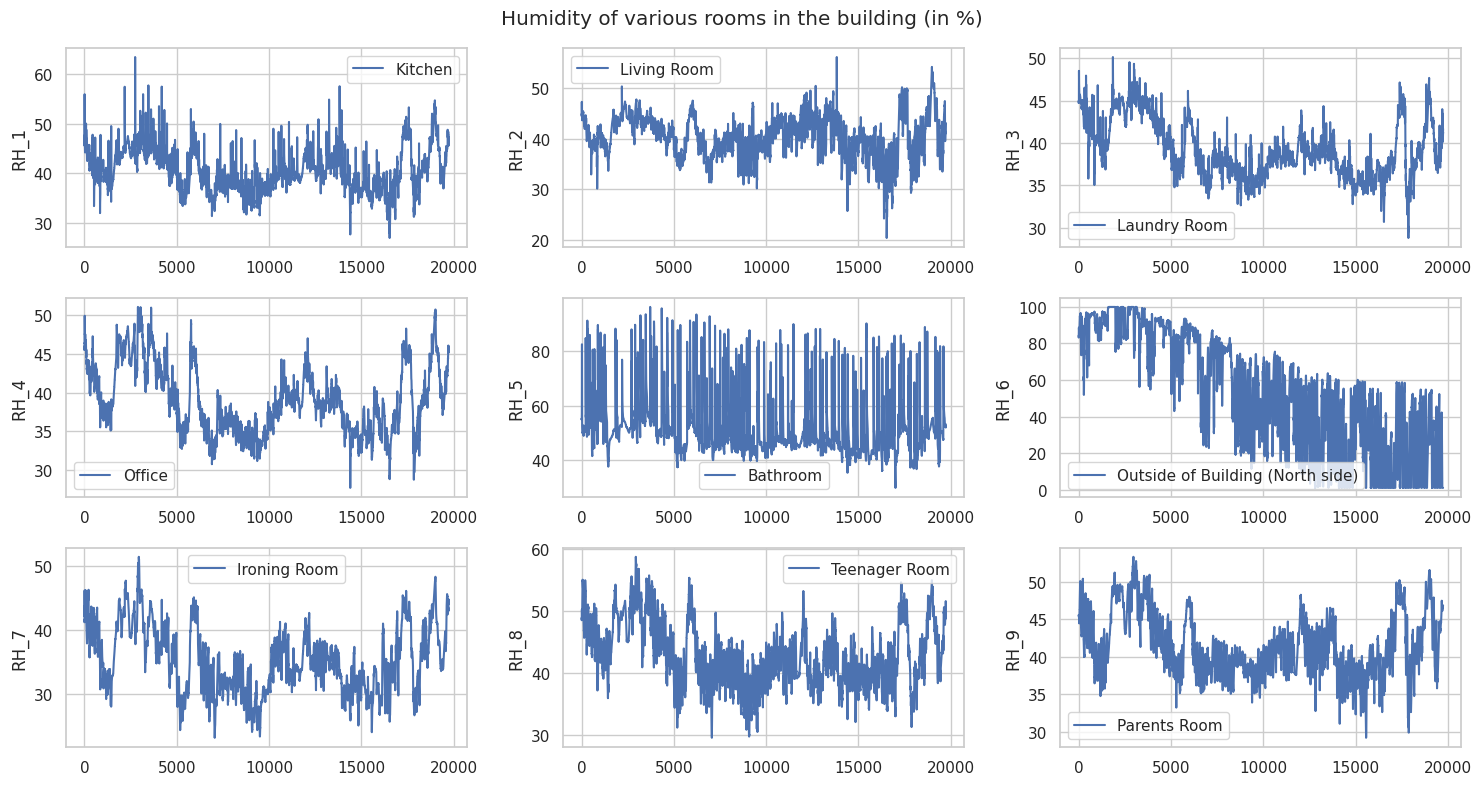

In [ ]:
humd_cols = ['RH_1', 'RH_2', 'RH_3', 'RH_4', 'RH_5', 'RH_6', 'RH_7', 'RH_8', 'RH_9']

ts_plot(df, humd_cols, 3, 3, labels, title='Humidity of various rooms in the building (in %)')

Humidity measurements inside the building is more or less constant (e.g. no trend observed).
Humidity outside the Building (North side) is decreased over the time (from Jan to May) which is strange as humidity is lower in winter and higher in summer.

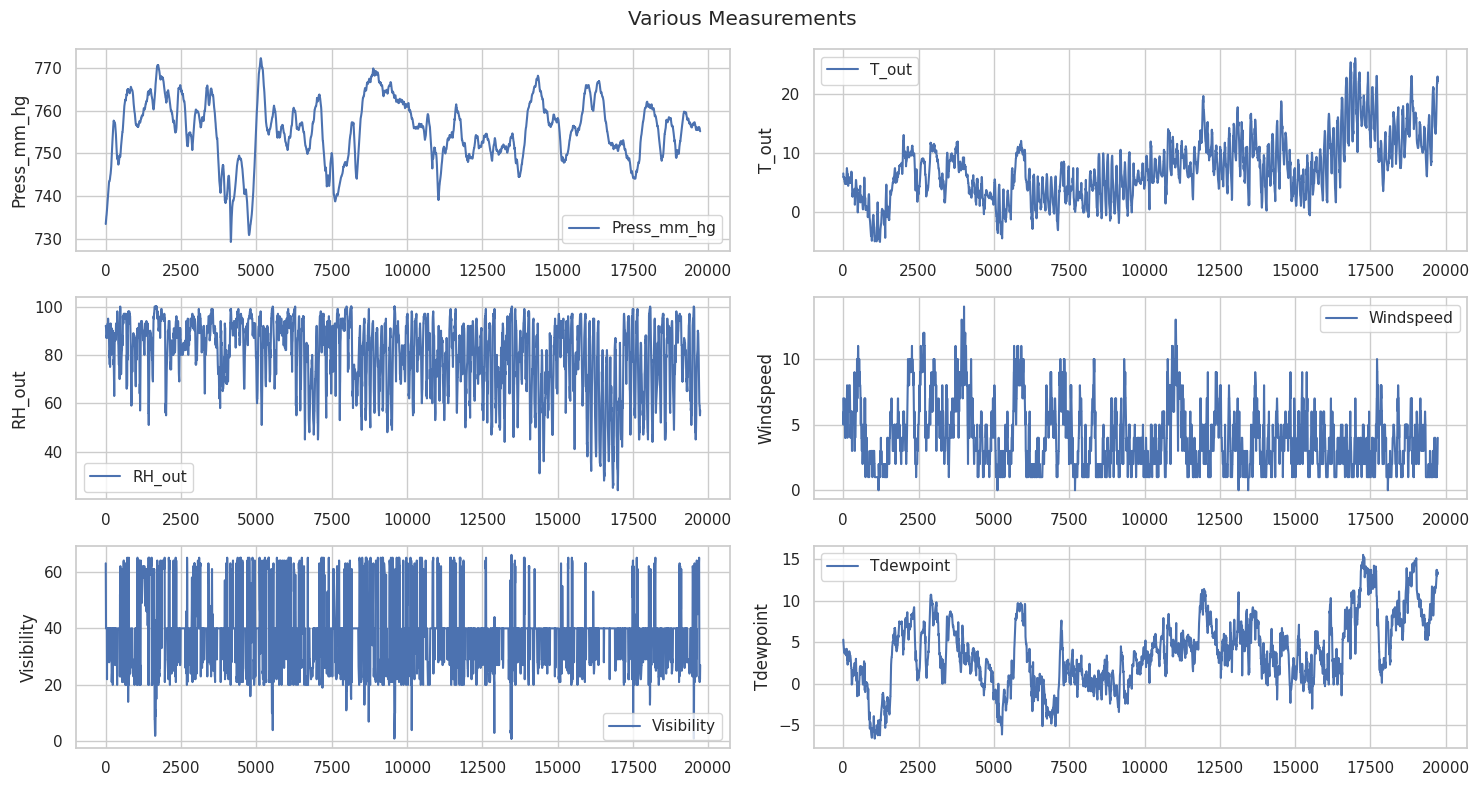

In [ ]:
# Plot features other than temperature and humidity
cols = ['Press_mm_hg', 'T_out', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint']

ts_plot(df, cols, 3, 2, cols, title='Various Measurements')

# Spliting data into train and test

In [ ]:
from sklearn.model_selection import train_test_split

# Spliting dataset into train and test
df_train, df_test = train_test_split(df, test_size=0.20, random_state=0)
print(df_train.shape, df_test.shape)


(15788, 32) (3947, 32)


# 6. Feature Analysis

In [ ]:
# Checking zero variance columns

num_zero_var = 0
for i, icol in enumerate(df_train.columns[1:]):   # Skip date column

    if df_train[icol].var() == 0:
        num_zero_var += 1

print(f'Total {num_zero_var} columns have zero variance')

Total 0 columns have zero variance


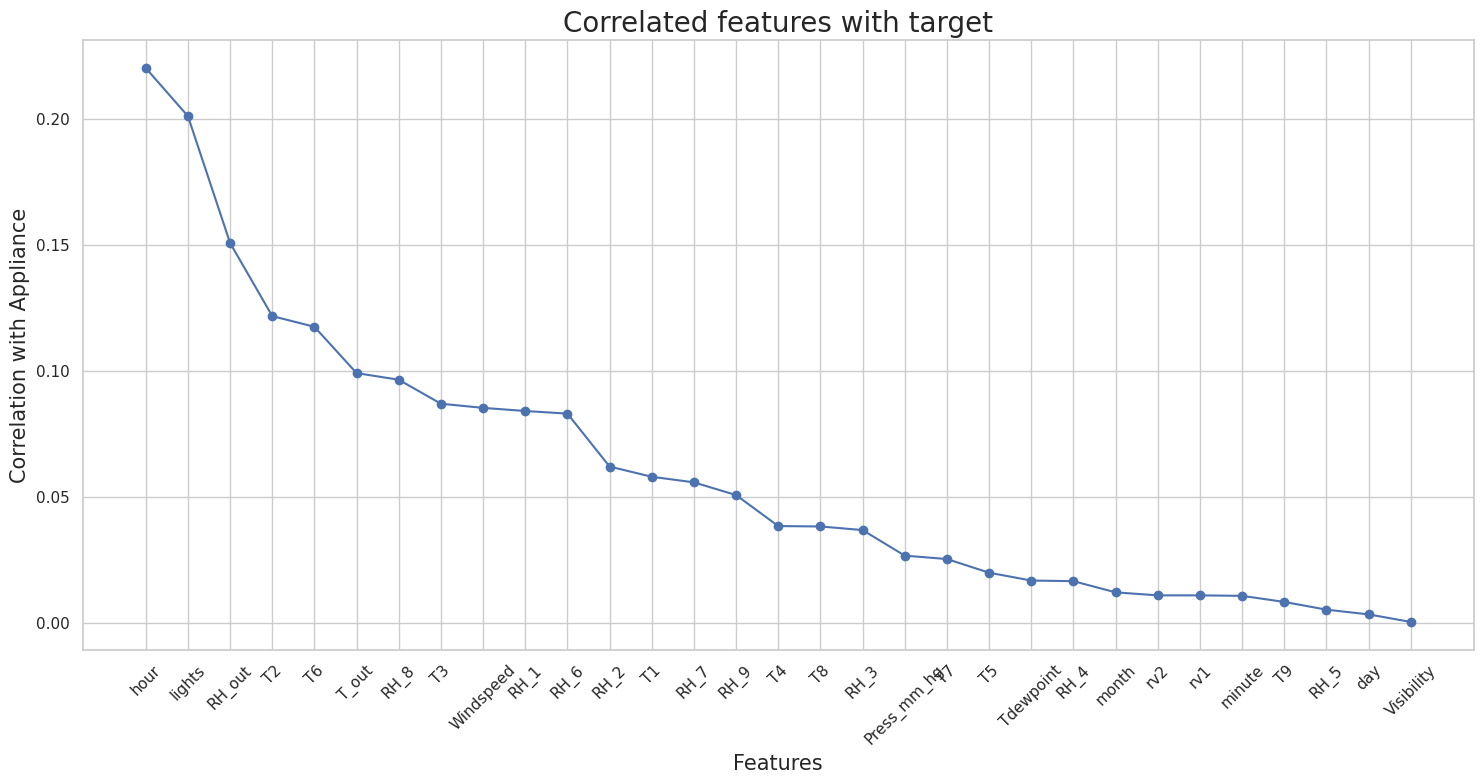

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Calculate correlation directly for all features at once
temp_df = df_train.drop("Appliances", axis=1)
corr_df = (
    temp_df.corrwith(df_train["Appliances"])
    .abs()
    .reset_index(name="val")
    .rename(columns={"index": "cols"})
    .sort_values(by="val", ascending=False)
    .dropna()
)

# Plotting
plt.figure(figsize=(15, 8))
plt.plot(corr_df["cols"], corr_df["val"], marker="o")
plt.xlabel("Features", fontsize=15)
plt.ylabel("Correlation with Appliance", fontsize=15)
plt.title("Correlated features with target", fontsize=20)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Lights is highly correlated feature with Appliances
Visibility is least correlated feature with Appliance

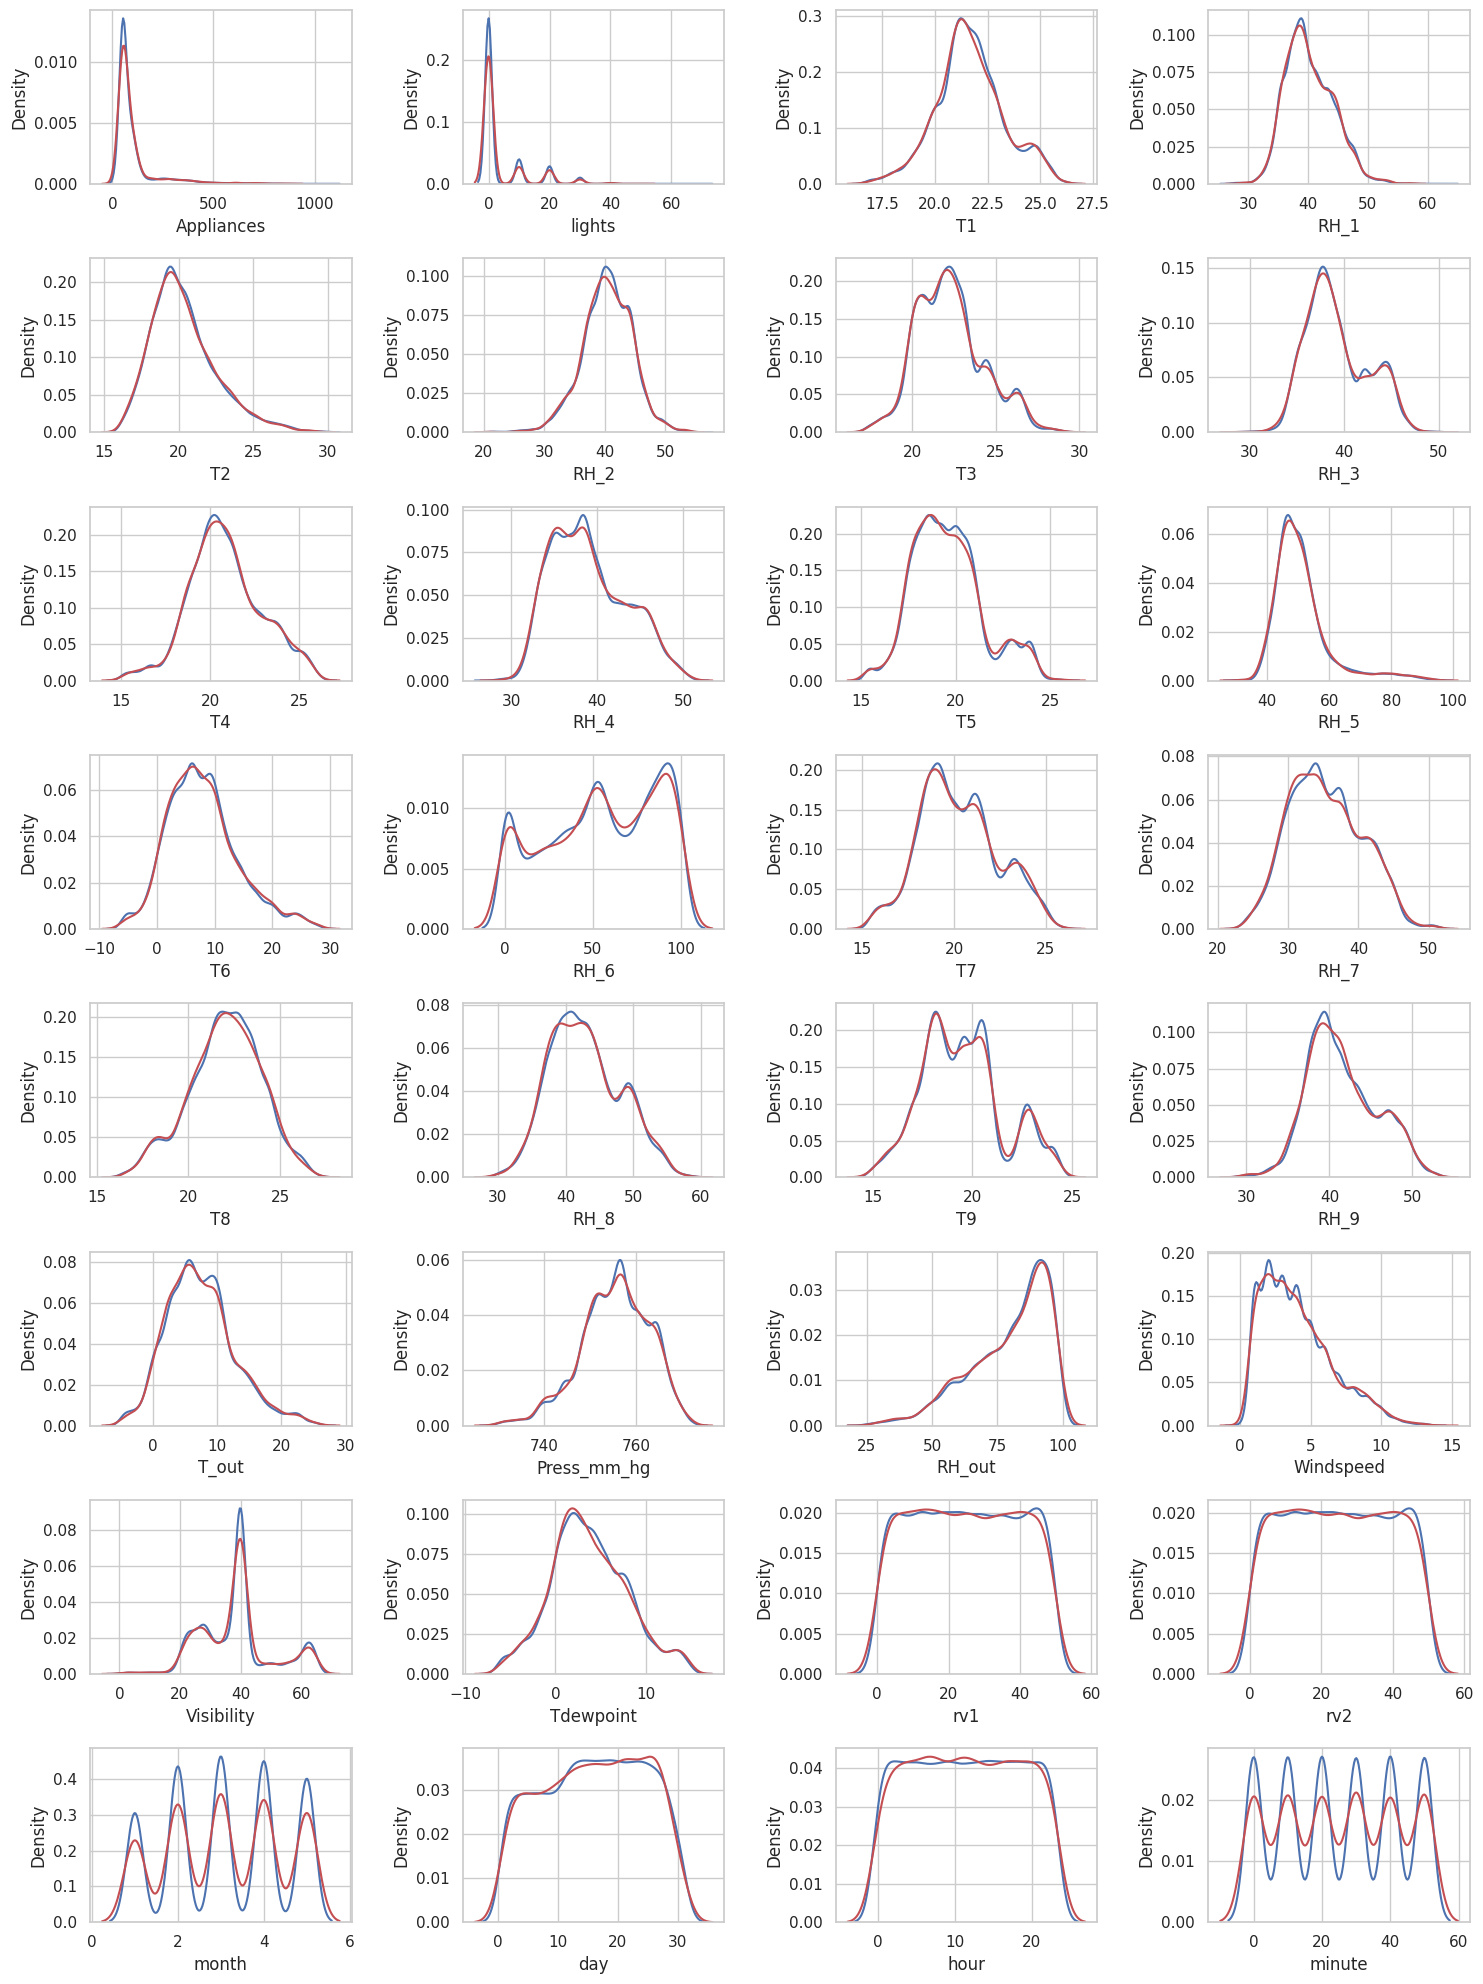

In [ ]:
# Check for distribution of train and test data for all the features

fig, ax = plt.subplots(8, 4, figsize=(15, 20))
ax = ax.flatten()

for i, icol in enumerate(df_train.columns):
    sns.kdeplot(data=df_train, x=icol, color='b', ax=ax[i])
    sns.kdeplot(data=df_test, x=icol, color='r', ax=ax[i])

plt.tight_layout()
plt.show()

Here Appliances is the target variable with positively skewed distribution
lights also has positively skewed distribution
Rest of the features are normally distributed
Also, train and test split are rantom so we don't have any dataset shifts/covariate shifts which we can see in above distribution plots.

In [ ]:
df_temp = df.copy()
df_temp['Appliances'] = df['Appliances']

crr_mat = df_temp.corr()
crr_mat['Appliances'].sort_values(ascending=False)


,Appliances
Appliances,1.000000
hour,0.216792
lights,0.197278
T2,0.120073
T6,0.117638
T_out,0.099155
Windspeed,0.087122
RH_1,0.086031
T3,0.085060
T1,0.055447


In [ ]:
df.Appliances.max()

1080

In [ ]:
df.lights.value_counts()

,count
lights,
0,15252
10,2212
20,1624
30,559
40,77
50,9
70,1
60,1


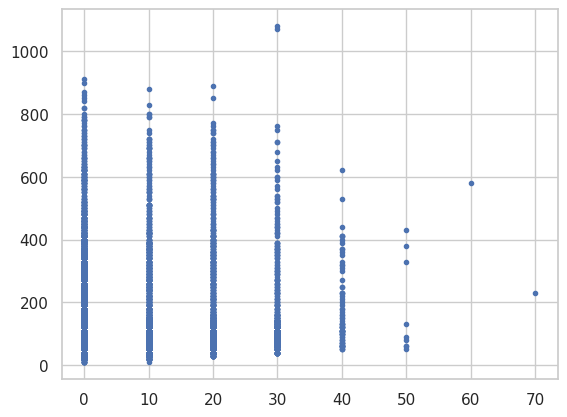

In [ ]:
plt.plot(df.lights, df.Appliances, 'b.')
plt.show()

In [ ]:
# Seperate features and target variable for both train and test data

drop_cols = ['Appliances', 'rv1', 'rv2']
X_train = df_train.drop(drop_cols, axis=1)
y_train = df_train['Appliances']

X_test = df_test.drop(drop_cols, axis=1)
y_test = df_test['Appliances']

print(f'Train data: {X_train.shape, y_train.shape}')
print(f'Test data: {X_test.shape, y_test.shape}')

Train data: ((15788, 29), (15788,))
Test data: ((3947, 29), (3947,))


# 8. Feature Selection

In [ ]:
# rfecv
rfe_estimator = RandomForestRegressor()
rfecv_1 = RFECV(rfe_estimator, step=1, min_features_to_select=1, scoring='r2', verbose=12, n_jobs=-1)

# Drop the 'date' column if it exists in X_train since it is a datetime dtype
X_train_numeric = X_train.drop('date', axis=1, errors='ignore')

rfecv_1.fit(X_train_numeric, y_train)
X_rfe = rfecv_1.transform(X_train_numeric)

plt.plot(rfecv_1.grid_scores_[:])
plt.show()

Fitting estimator with 28 features.
Fitting estimator with 27 features.
Fitting estimator with 26 features.


# 9. Model Building and Evaluation

In [ ]:
lr = LinearRegression() # Ridge()
lr.fit(X_train, y_train)

print(y_test.shape, y_pred.shape)

print(f'Training R2 score (LR): {r2_score(y_train, lr.predict(X_train))}')
print(f'Validation R2 Score (LR): {r2_score(y_test, y_pred)}')

(3947,) (3947,)
Training R2 score (LR): 0.16897609446599093
Validation R2 Score (LR): 0.17085631370461407


# 10 R2 score

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 4. TRAIN AND EVALUATE
lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)
print("Shapes:", y_test.shape, y_pred.shape)

print(f'Training R2 score (LR): {r2_score(y_train, lr.predict(X_train)):.4f}')
print(f'Validation R2 Score (LR): {r2_score(y_test, y_pred):.4f}')

Shapes: (3947,) (3947,)
Training R2 score (LR): 0.1690
Validation R2 Score (LR): 0.1709


In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
import pandas as pd

# --- Code to ensure 'df' is defined and processed ---
# Loading dataset from the official UCI repository
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00374/energydata_complete.csv'
df = pd.read_csv(url)

df['date'] = pd.to_datetime(df['date'])

df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['hour'] = df['date'].dt.hour
df['minute'] = df['date'].dt.minute

df.drop('date', axis=1, inplace=True)
# --- End of 'df' definition and processing ---

# Spliting dataset into train and test
df_train, df_test = train_test_split(df, test_size=0.20, random_state=0)

# Define X_train, y_train, X_test, y_test
drop_cols = ['Appliances', 'rv1', 'rv2']
X_train = df_train.drop(drop_cols, axis=1)
y_train = df_train['Appliances']

X_test = df_test.drop(drop_cols, axis=1)
y_test = df_test['Appliances']

# 4. INITIALIZE, TRAIN AND EVALUATE XGBOOST
xgb = XGBRegressor()
xgb.fit(X_train, y_train)

y_pred = xgb.predict(X_test)
print("Shapes:", y_test.shape, y_pred.shape)

print(f'Training R2 score (XGB): {r2_score(y_train, xgb.predict(X_train)):.4f}')
print(f'Validation R2 Score (XGB): {r2_score(y_test, y_pred):.4f}')

Shapes: (3947,) (3947,)
Training R2 score (XGB): 0.8684
Validation R2 Score (XGB): 0.5080


# 11.Optional variables passed into the function so it can operate on dynamic data.

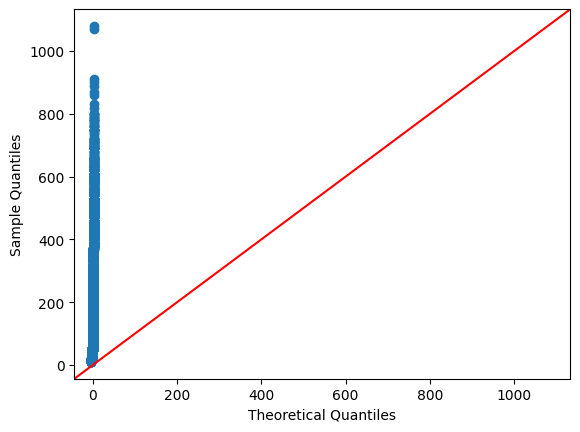

In [3]:
import numpy as np
import pandas as pd
import plotly.express as px
from sklearn.neighbors import LocalOutlierFactor
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
import pylab as py

# Ensure X_train and y_train are defined in the current session
if 'X_train' not in locals() or 'y_train' not in locals():
    url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00374/energydata_complete.csv'
    df = pd.read_csv(url)
    df['date'] = pd.to_datetime(df['date'])
    df['month'] = df['date'].dt.month
    df['day'] = df['date'].dt.day
    df['hour'] = df['date'].dt.hour
    df['minute'] = df['date'].dt.minute
    df.drop('date', axis=1, inplace=True)

    df_train, df_test = train_test_split(df, test_size=0.20, random_state=0)
    drop_cols = ['Appliances', 'rv1', 'rv2']
    X_train = df_train.drop(drop_cols, axis=1)
    y_train = df_train['Appliances']

# Outlier detection using the input variables
# Implementing LOF for the outlier detection
lof = LocalOutlierFactor(n_neighbors=20, contamination=.03)

y_pred = lof.fit_predict(X_train)

lofs_index = np.where(y_pred==-1)

arr = list(lofs_index[0])
values = X_train[X_train.index.isin(arr)]
X_train['outlier'] = X_train.index.isin(values.index).astype(int)

outlier_df = X_train.copy()
outlier_df['Appliances'] = y_train.tolist()
X_train = X_train.drop('outlier', axis=1)

fig = px.box(outlier_df, y="Appliances", color="outlier",
             notched=True,
             title="Energy usage for regular data points and the data points with outliers"
            )
fig.show(renderer="colab")

sm.qqplot(outlier_df['Appliances'], line='45')
py.show()



# 12 XGBoost Regressor Performance Evaluation on Energy Dataset



#

In [5]:
#Model Evaluation
import numpy as np
from sklearn import metrics

# Ensure y_test and y_pred exist; if not, recreate them using the trained xgb model
if 'y_test' not in locals() or 'y_pred' not in locals():
    from sklearn.model_selection import train_test_split
    import pandas as pd
    from xgboost import XGBRegressor

    url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00374/energydata_complete.csv'
    df = pd.read_csv(url)
    df['date'] = pd.to_datetime(df['date'])
    df['month'] = df['date'].dt.month
    df['day'] = df['date'].dt.day
    df['hour'] = df['date'].dt.hour
    df['minute'] = df['date'].dt.minute
    df.drop('date', axis=1, inplace=True)

    df_train, df_test = train_test_split(df, test_size=0.20, random_state=0)
    drop_cols = ['Appliances', 'rv1', 'rv2']
    X_train = df_train.drop(drop_cols, axis=1)
    y_train = df_train['Appliances']
    X_test = df_test.drop(drop_cols, axis=1)
    y_test = df_test['Appliances']

    xgb = XGBRegressor()
    xgb.fit(X_train, y_train)
    y_pred = xgb.predict(X_test)

meanAbErr = metrics.mean_absolute_error(y_test, y_pred)
meanSqErr = metrics.mean_squared_error(y_test, y_pred)
rootMeanSqErr = np.sqrt(meanSqErr)

# Using the active model (xgb) and its corresponding training datasets
print('R squared: {:.2f}'.format(xgb.score(X_train, y_train)*100))
print('Mean Absolute Error:', meanAbErr)
print('Mean Square Error:', meanSqErr)
print('Root Mean Square Error:', rootMeanSqErr)

R squared: 86.84
Mean Absolute Error: 37.15010452270508
Mean Square Error: 5605.13818359375
Root Mean Square Error: 74.86747079736132
